In [17]:
# IMPORTS AND SETUP
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,precision_recall_fscore_support
from sklearn.metrics import f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.utils import class_weight
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.over_sampling import SMOTE

In [18]:
# LOAD DATA
df1 = pd.read_csv("datasets/dataset1.csv")
df2 = pd.read_csv("datasets/dataset2.csv")
df = pd.concat([df1, df2], axis=0, ignore_index=True)
df

C:\Users\adity\AppData\Local\Temp\ipykernel_14260\3401764481.py:2: DtypeWarning: Columns (1,3,47) have mixed types. Specify dtype option on import or set low_memory=False.
  df1 = pd.read_csv("datasets/dataset1.csv")


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,Label
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699996,59.166.0.8,12520,149.171.126.6,31010,tcp,FIN,0.020383,320,1874,31,...,0,8,20,7,5,1,1,4,NaN,0
699997,59.166.0.0,18895,149.171.126.9,80,tcp,FIN,1.402957,19410,1087890,31,...,0,1,1,2,7,2,2,2,NaN,0
699998,59.166.0.0,30103,149.171.126.5,5190,tcp,FIN,0.007108,2158,2464,31,...,0,13,13,6,7,2,1,2,NaN,0
699999,59.166.0.6,30388,149.171.126.5,111,udp,CON,0.004435,568,304,31,...,0,10,13,6,5,1,1,3,NaN,0


In [19]:
# DROP UNNECESSARY COLUMNS
df = df.drop(columns=['srcip', 'dstip', 'Stime', 'Ltime', 'sport', 'dsport'])

In [20]:
# ENCODE CATEGORICAL VARIABLES
categorical_cols = ['proto', 'state', 'service']
df = pd.get_dummies(df, columns=categorical_cols)

# encode the 'attack_cat' column
df['attack_cat'] = LabelEncoder().fit_transform(df['attack_cat'].astype(str))

## PART 1

In [5]:
X = df.drop(columns=['attack_cat', 'Label'])  # drop both to avoid leakage
y = df['Label']
X_train, X_test, y_train, y_test = train_test_split(StandardScaler().fit_transform(X), y, test_size=0.2, stratify=y, random_state=42)

In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, BatchNormalization

num_classes = len(y.unique())

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dense(num_classes, activation='sigmoid')
])

In [7]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(class_weight='balanced',
                                                  classes=np.unique(y_train),
                                                  y=y_train)

class_weights_dict = dict(enumerate(class_weights))

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy']) 

model.fit(X_train, y_train, epochs=20, batch_size=128, validation_split=0.2,
          class_weight=class_weights_dict)

Epoch 1/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.9483 - loss: 0.1113 - val_accuracy: 0.9938 - val_loss: 0.0192
Epoch 2/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.9934 - loss: 0.0205 - val_accuracy: 0.9942 - val_loss: 0.0223
Epoch 3/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9940 - loss: 0.0173 - val_accuracy: 0.9943 - val_loss: 0.0224
Epoch 4/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9946 - loss: 0.0152 - val_accuracy: 0.9940 - val_loss: 0.0271
Epoch 5/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9944 - loss: 0.0154 - val_accuracy: 0.9945 - val_loss: 0.0240
Epoch 6/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9946 - loss: 0.0153 - val_accuracy: 0.9943 - val_loss: 0.0256
Epoch 7/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9943 - loss: 0.0152 - val_accuracy: 0.9946 - val_loss: 0.0299
Epoch 8/20
3500/3500 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9946 - loss: 0.014

In [8]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)
y_pred_labels = y_pred.argmax(axis=1)
print(classification_report(y_test, y_pred_labels))

4376/4376 ━━━━━━━━━━━━━━━━━━━━ 4s 985us/step
              precision    recall  f1-score   support

           0       1.00      0.99      1.00    135558
           1       0.85      1.00      0.92      4443

    accuracy                           0.99    140001
   macro avg       0.92      1.00      0.96    140001
weighted avg       1.00      0.99      0.99    140001



## PART 2

In [23]:
df1 = pd.read_csv("datasets/dataset1.csv")
df2 = pd.read_csv("datasets/dataset2.csv")
df = pd.concat([df1, df2], ignore_index=True)
df.drop(columns=['srcip', 'dstip', 'Stime', 'Ltime', 'sport', 'dsport'], inplace=True)
df = df.dropna()

# One-hot encoding categorical features
categorical_cols = ['proto', 'state', 'service']
df = pd.get_dummies(df, columns=categorical_cols)

# Encode target label
df['attack_cat'] = df['attack_cat'].astype('category').cat.codes

# Define features and target
X = df.drop(columns=['attack_cat'])
y = df['attack_cat']

sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X, y)
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, stratify=y_res, random_state=42)

C:\Users\adity\AppData\Local\Temp\ipykernel_14260\1889334120.py:1: DtypeWarning: Columns (1,3,47) have mixed types. Specify dtype option on import or set low_memory=False.
  df1 = pd.read_csv("datasets/dataset1.csv")


In [13]:
from sklearn.ensemble import VotingClassifier


dt_clf = DecisionTreeClassifier(max_depth=10, min_samples_leaf=10, class_weight='balanced', random_state=42)
rf_clf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

hybrid_model = VotingClassifier(estimators=[
    ('decision_tree', dt_clf),
    ('random_forest', rf_clf)
], voting='soft')

hybrid_model.fit(X_train, y_train)
y_pred = hybrid_model.predict(X_test)

In [14]:
print("Hybrid Model Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Macro F1 Score:", f1_score(y_test, y_pred, average='macro'))


Hybrid Model Accuracy: 0.7488183161004431
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.75      0.82      1504
           1       0.42      0.57      0.48      1504
           2       0.41      0.48      0.44      1505
           3       0.63      0.48      0.54      1505
           4       0.80      0.61      0.69      1505
           5       0.99      0.94      0.97      1504
           6       0.93      0.93      0.93      1505
           7       0.89      0.98      0.93      1504
           8       0.95      1.00      0.97      1504

    accuracy                           0.75     13540
   macro avg       0.77      0.75      0.75     13540
weighted avg       0.77      0.75      0.75     13540

Macro F1 Score: 0.7539136126910322


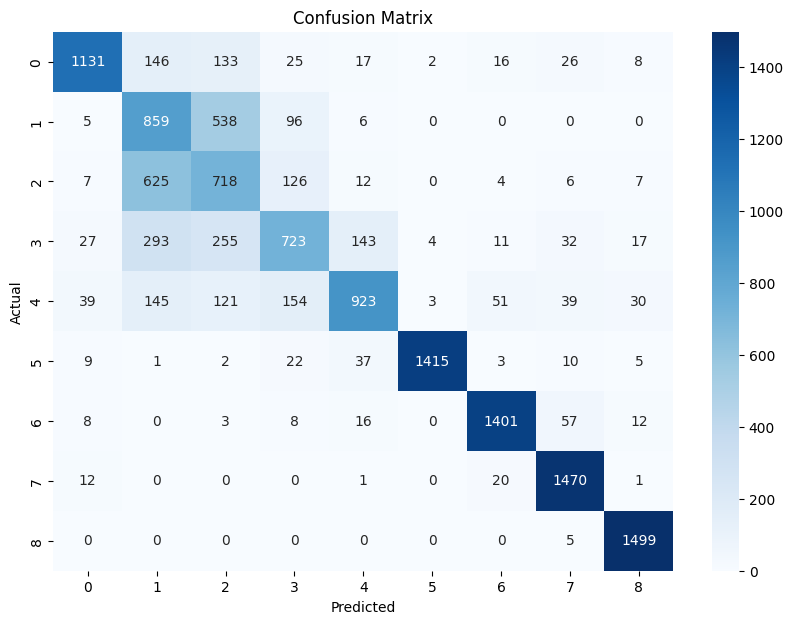

In [15]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()
